## Bagging Step by Step:

Bagging (bootstrap aggregating) trains several models on different random samples of the training data, then combines their predictions. This notebook builds it by hand: draw three bootstrap samples, train one decision tree on each, and combine the trees by majority vote. It ends with the three sampling variants of bagging: pasting, random subspaces and random patches.

The data is deliberately tiny (versicolor vs virginica, two features, 10 training rows) so every tree and decision region is easy to read.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
from mlxtend.plotting import plot_decision_regions

## 1. Prepare the data:

In [2]:
df = sns.load_dataset('iris')
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
encoder = LabelEncoder()
df['species'] = encoder.fit_transform(df['species'])
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Keep two classes (versicolor = 1, virginica = 2) and two features, so the decision regions can be plotted in 2D.

In [4]:
df = df[df['species'] != 0][['sepal_width', 'petal_length', 'species']]
df.head()

,sepal_width,petal_length,species
50,3.2,4.7,1
51,3.2,4.5,1
52,3.1,4.9,1
53,2.3,4.0,1
54,2.8,4.6,1


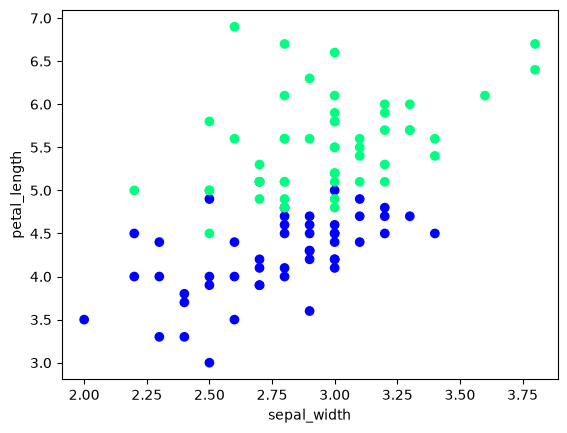

In [5]:
plt.scatter(df['sepal_width'], df['petal_length'], c=df['species'], cmap='winter')
plt.xlabel('sepal_width')
plt.ylabel('petal_length')
plt.show()

Shuffle once with a fixed seed, then take small, non-overlapping sets: 10 rows to train on, 5 to check each tree on (validation), and 5 for the final test.

In [6]:
df = df.sample(frac=1, random_state=42)

df_train = df.iloc[:10]
df_val = df.iloc[10:15]
df_test = df.iloc[15:20]

X_val, y_val = df_val.iloc[:, 0:2].values, df_val.iloc[:, -1].values
X_test, y_test = df_test.iloc[:, 0:2].values, df_test.iloc[:, -1].values

df_train

,sepal_width,petal_length,species
133,2.8,5.1,2
103,2.9,5.6,2
120,3.2,5.7,2
95,3.0,4.2,1
94,2.7,4.2,1
89,2.5,4.0,1
72,2.5,4.9,1
130,2.8,6.1,2
60,2.0,3.5,1
50,3.2,4.7,1


## 2. Bagging: three trees on bootstrap samples:

`evaluate` fits a tree, plots it with its decision regions, and prints its accuracy on the validation set.

In [7]:
def evaluate(clf, X, y):
    clf.fit(X.values, y.values)

    plot_tree(clf, feature_names=list(X.columns), filled=True)
    plt.show()

    plot_decision_regions(X.values, y.values, clf=clf, legend=2)
    plt.show()

    print("Validation accuracy:", accuracy_score(y_val, clf.predict(X_val)))

Each bootstrap sample draws 8 rows **with replacement** from the training set, so some rows repeat and others are left out. That is what makes the three trees different from each other.

In [8]:
# Tree 1: bootstrap sample
df_bag1 = df_train.sample(8, replace=True, random_state=1)

X_bag1 = df_bag1.iloc[:, 0:2]
y_bag1 = df_bag1.iloc[:, -1]

df_bag1

,sepal_width,petal_length,species
89,2.5,4.0,1
60,2.0,3.5,1
50,3.2,4.7,1
89,2.5,4.0,1
133,2.8,5.1,2
133,2.8,5.1,2
103,2.9,5.6,2
130,2.8,6.1,2


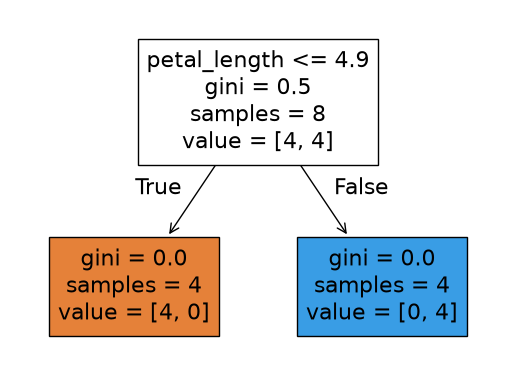

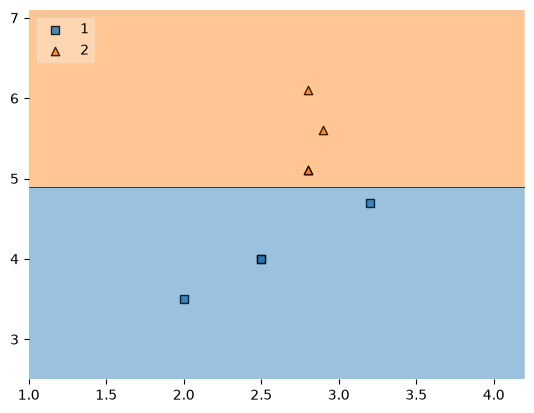

Validation accuracy: 0.8


In [9]:
dt_bag1 = DecisionTreeClassifier(random_state=42)
evaluate(dt_bag1, X_bag1, y_bag1)

In [10]:
# Tree 2: bootstrap sample
df_bag2 = df_train.sample(8, replace=True, random_state=2)

X_bag2 = df_bag2.iloc[:, 0:2]
y_bag2 = df_bag2.iloc[:, -1]

df_bag2

,sepal_width,petal_length,species
60,2.0,3.5,1
60,2.0,3.5,1
72,2.5,4.9,1
120,3.2,5.7,2
60,2.0,3.5,1
130,2.8,6.1,2
120,3.2,5.7,2
103,2.9,5.6,2


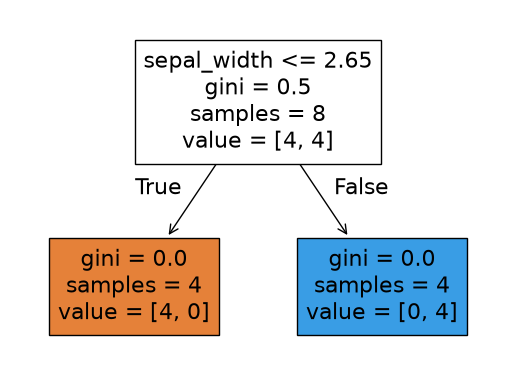

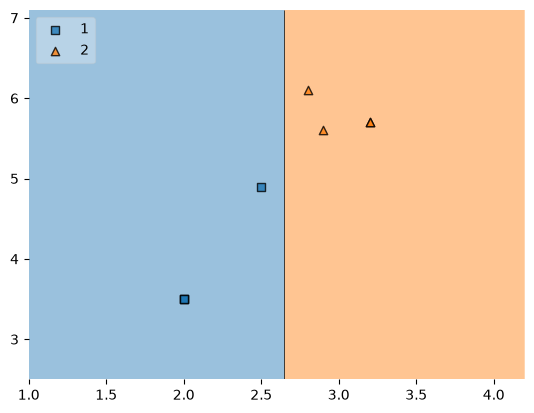

Validation accuracy: 0.8


In [11]:
dt_bag2 = DecisionTreeClassifier(random_state=42)
evaluate(dt_bag2, X_bag2, y_bag2)

In [12]:
# Tree 3: bootstrap sample
df_bag3 = df_train.sample(8, replace=True, random_state=3)

X_bag3 = df_bag3.iloc[:, 0:2]
y_bag3 = df_bag3.iloc[:, -1]

df_bag3

,sepal_width,petal_length,species
60,2.0,3.5,1
50,3.2,4.7,1
95,3.0,4.2,1
60,2.0,3.5,1
60,2.0,3.5,1
133,2.8,5.1,2
89,2.5,4.0,1
95,3.0,4.2,1


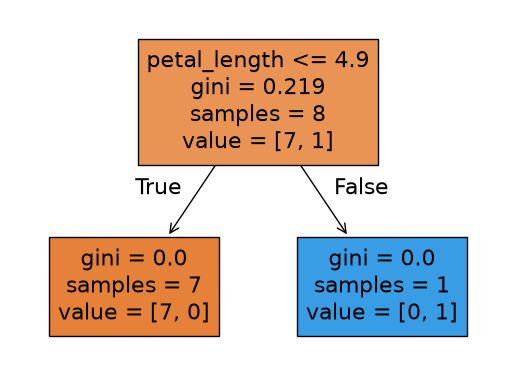

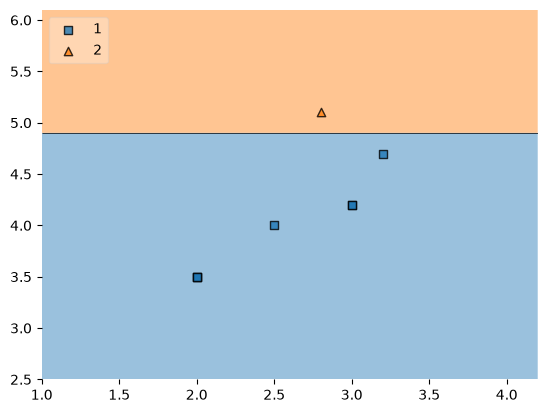

Validation accuracy: 0.8


In [13]:
dt_bag3 = DecisionTreeClassifier(random_state=42)
evaluate(dt_bag3, X_bag3, y_bag3)

## 3. Predict and combine:

First, one test point: each tree makes its own prediction, and the bagged prediction is the majority vote.

In [14]:
trees = [dt_bag1, dt_bag2, dt_bag3]

x_point = X_test[:1]
point_preds = [tree.predict(x_point)[0] for tree in trees]

for i, p in enumerate(point_preds, 1):
    print(f"Tree {i} predicts:", p)

print("Majority vote:", pd.Series(point_preds).mode()[0])
print("True class:   ", y_test[0])

Tree 1 predicts: 1
Tree 2 predicts: 2
Tree 3 predicts: 1
Majority vote: 1
True class:    1


Now the whole test set: compare each tree's accuracy with the accuracy of the majority vote. With only 10 training rows, the result depends on the random seeds, so don't read much into a single run.

In [15]:
all_preds = np.vstack([tree.predict(X_test) for tree in trees])
y_vote = pd.DataFrame(all_preds).mode(axis=0).iloc[0].astype(int).values

for i, p in enumerate(all_preds, 1):
    print(f"Tree {i} test accuracy:", accuracy_score(y_test, p))

print("Bagged (majority vote) test accuracy:", accuracy_score(y_test, y_vote))

Tree 1 test accuracy: 0.8
Tree 2 test accuracy: 0.8
Tree 3 test accuracy: 0.8
Bagged (majority vote) test accuracy: 0.8


## 4. Types of bagging:

### Pasting:
- Row sampling **without** replacement (no duplicate rows).

In [16]:
df_train.sample(8, random_state=42)

,sepal_width,petal_length,species
60,2.0,3.5,1
103,2.9,5.6,2
89,2.5,4.0,1
133,2.8,5.1,2
130,2.8,6.1,2
120,3.2,5.7,2
50,3.2,4.7,1
94,2.7,4.2,1


### Random subspaces:
- Column sampling, with or without replacement (duplicate columns are allowed only with replacement).

In [17]:
df_iris = sns.load_dataset('iris').sample(10, random_state=42)
df_iris

,sepal_length,sepal_width,petal_length,petal_width,species
73,6.1,2.8,4.7,1.2,versicolor
18,5.7,3.8,1.7,0.3,setosa
118,7.7,2.6,6.9,2.3,virginica
78,6.0,2.9,4.5,1.5,versicolor
76,6.8,2.8,4.8,1.4,versicolor
31,5.4,3.4,1.5,0.4,setosa
64,5.6,2.9,3.6,1.3,versicolor
141,6.9,3.1,5.1,2.3,virginica
68,6.2,2.2,4.5,1.5,versicolor
82,5.8,2.7,3.9,1.2,versicolor


In [18]:
# Without replacement: two different columns
df_iris.sample(2, axis=1, random_state=42)

,sepal_width,species
73,2.8,versicolor
18,3.8,setosa
118,2.6,virginica
78,2.9,versicolor
76,2.8,versicolor
31,3.4,setosa
64,2.9,versicolor
141,3.1,virginica
68,2.2,versicolor
82,2.7,versicolor


In [19]:
# With replacement: the same column can be picked twice
df_iris.sample(2, replace=True, axis=1, random_state=42)

,petal_width,species
73,1.2,versicolor
18,0.3,setosa
118,2.3,virginica
78,1.5,versicolor
76,1.4,versicolor
31,0.4,setosa
64,1.3,versicolor
141,2.3,virginica
68,1.5,versicolor
82,1.2,versicolor


### Random patches:
- A combination of pasting and random subspaces: rows and columns are both sampled (here with replacement, so duplicate rows and columns are allowed).

In [20]:
df_iris.sample(8, replace=True, random_state=42).sample(2, replace=True, axis=1, random_state=42)

,petal_width,species
64,1.3,versicolor
78,1.5,versicolor
141,2.3,virginica
76,1.4,versicolor
64,1.3,versicolor
82,1.2,versicolor
118,2.3,virginica
64,1.3,versicolor
